In [1]:
import pandas as pd
import numpy as np

train = pd.read_parquet("../data/processed/train.parquet")
valid = pd.read_parquet("../data/processed/valid.parquet")

target = "isFraud"
drop = ["TransactionID", "TransactionDT", "day", target]

cat_cols = ["ProductCD", "card4", "card6"] + [f"M{i}" for i in range(1, 10)]
num_cols = [c for c in train.select_dtypes(include="number").columns if c not in drop]

print(len(num_cols), "numeric,", len(cat_cols), "categorical")

401 numeric, 12 categorical


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

numeric = Pipeline([
    # fill NaN with the median, and add a 0/1 "was missing" column
    # so the model can still use missingness as a signal
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    # put features on the same scale so no column dominates
    ("scale", StandardScaler()),
])

categorical = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
    # categories the model hasn't seen in training get ignored, not an error
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

prep = ColumnTransformer([
    ("num", numeric, num_cols),
    ("cat", categorical, cat_cols),
])

model = Pipeline([
    ("prep", prep),
    ("clf", LogisticRegression(max_iter=1000)),
])

model.fit(train[num_cols + cat_cols], train[target])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](413,)","['TransactionAmt','card1','card2',...,'M7','M8','M9']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,413
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere 

In [3]:
p_valid = model.predict_proba(valid[num_cols + cat_cols])[:, 1]

print("PR-AUC: ", round(average_precision_score(valid[target], p_valid), 4))
print("ROC-AUC:", round(roc_auc_score(valid[target], p_valid), 4))
print("Random PR-AUC would be about:", round(valid[target].mean(), 4))

PR-AUC:  0.1866
ROC-AUC: 0.8233
Random PR-AUC would be about: 0.0342


In [5]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score

train = pd.read_parquet("../data/processed/train.parquet")
valid = pd.read_parquet("../data/processed/valid.parquet")

target = "isFraud"
drop = ["TransactionID", "TransactionDT", "day", target]

cat_cols = train.select_dtypes(exclude="number").columns.tolist()

unseen = {}
for c in cat_cols:
    train[c] = train[c].astype("category")
    known = train[c].cat.categories
    is_new = valid[c].notna() & ~valid[c].isin(known)
    unseen[c] = int(is_new.sum())
    valid[c] = pd.Categorical(valid[c].where(~is_new), categories=known)

features = [c for c in train.columns if c not in drop]
print(len(features), "features,", len(cat_cols), "categorical")
print({k: v for k, v in unseen.items() if v > 0})

fit_part = train[train["day"] <= 120]
stop_part = train[train["day"] > 120]

432 features, 31 categorical
{'id_30': 142, 'id_31': 8068, 'id_33': 77, 'DeviceInfo': 336}


In [7]:
# put both periods together in time order, so validation rows can see
# their own past (including late training days), exactly as in production
full = pd.concat([train.assign(_set="train"), valid.assign(_set="valid")])
full = full.sort_values("TransactionDT").reset_index(drop=True)

# 1. rebuild an approximate card-holder ID
full["card_start"] = (full["day"] - full["D1"]).round()
full["uid"] = (full["card1"].astype(str) + "_"
               + full["addr1"].astype(str) + "_"
               + full["card_start"].astype(str))

g = full.groupby("uid")

# 2. how many times have we seen this card before?
full["uid_prior_count"] = g.cumcount()

# 3. hours since this card's previous transaction (bursts are suspicious)
full["uid_hours_since_prev"] = g["TransactionDT"].diff() / 3600

# 4. is this amount unusual for this card? compare with its PAST average only
past_mean = g["TransactionAmt"].transform(lambda s: s.shift().expanding().mean())
full["uid_amt_vs_past_mean"] = full["TransactionAmt"] / past_mean

# 5. cents part of the amount: odd cents often mean foreign currency conversion
full["amt_cents"] = (full["TransactionAmt"] % 1).round(3)

# 6. hour of day (seconds into the day -> hour)
full["hour"] = (full["TransactionDT"] % 86400) // 3600

new_feats = ["uid_prior_count", "uid_hours_since_prev",
             "uid_amt_vs_past_mean", "amt_cents", "hour"]
print(full[new_feats].describe().T.round(2))

                         count    mean     std   min   25%    50%     75%  \
uid_prior_count       509531.0    6.03   44.05  0.00  0.00   1.00    4.00   
uid_hours_since_prev  313931.0  265.19  450.44  0.00  1.99  72.21  336.78   
uid_amt_vs_past_mean  313931.0    1.23    2.06  0.01  0.64   1.00    1.24   
amt_cents             574709.0    0.38    0.43  0.00  0.00   0.00    0.95   
hour                  574709.0   13.86    7.61  0.00  6.00  16.00   20.00   

                          max  
uid_prior_count       1409.00  
uid_hours_since_prev  4299.93  
uid_amt_vs_past_mean   204.00  
amt_cents                1.00  
hour                    23.00  


In [8]:
train = full[full["_set"] == "train"].drop(columns="_set")
valid = full[full["_set"] == "valid"].drop(columns="_set")

features2 = features + new_feats
fit_part = train[train["day"] <= 120]
stop_part = train[train["day"] > 120]

dfit = lgb.Dataset(fit_part[features2], fit_part[target])
dstop = lgb.Dataset(stop_part[features2], stop_part[target], reference=dfit)

booster2 = lgb.train(
    params, dfit, num_boost_round=3000, valid_sets=[dstop],
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)],
)

p_valid2 = booster2.predict(valid[features2], num_iteration=booster2.best_iteration)
print("Best trees:", booster2.best_iteration)
print("PR-AUC: ", round(average_precision_score(valid[target], p_valid2), 4))
print("ROC-AUC:", round(roc_auc_score(valid[target], p_valid2), 4))

Training until validation scores don't improve for 100 rounds
[200]	valid_0's average_precision: 0.622097
[400]	valid_0's average_precision: 0.64889
[600]	valid_0's average_precision: 0.659834
[800]	valid_0's average_precision: 0.663368
Early stopping, best iteration is:
[831]	valid_0's average_precision: 0.663915
Best trees: 831
PR-AUC:  0.5372
ROC-AUC: 0.9034


In [9]:
# A. how good is our ID?
print("Unique uids:", full["uid"].nunique())
print("Share of rows with a 'nan' in uid:",
      round(full["uid"].str.contains("nan").mean(), 3))
print("Transactions per uid (median):", full.groupby("uid").size().median())

# B. did the model use the new features?
imp = pd.Series(booster2.feature_importance("gain"), index=features2)
imp = (imp / imp.sum()).sort_values(ascending=False)
print("\nRank of new features out of", len(imp))
for f in new_feats:
    print(f"  {f}: rank {imp.index.get_loc(f) + 1}, share {imp[f]:.3%}")
print("\nTop 10 overall:")
print(imp.head(10).round(4))

Unique uids: 195600
Share of rows with a 'nan' in uid: 0.0
Transactions per uid (median): 1.0

Rank of new features out of 437
  uid_prior_count: rank 69, share 0.319%
  uid_hours_since_prev: rank 36, share 0.716%
  uid_amt_vs_past_mean: rank 46, share 0.637%
  amt_cents: rank 41, share 0.685%
  hour: rank 44, share 0.646%

Top 10 overall:
C1                0.0426
V258              0.0398
DeviceInfo        0.0358
card1             0.0322
V244              0.0317
C13               0.0314
card2             0.0301
C14               0.0281
TransactionAmt    0.0250
addr1             0.0235
dtype: float64


In [10]:
def run(feats, seed):
    p = {**params, "seed": seed}
    d1 = lgb.Dataset(fit_part[feats], fit_part[target])
    d2 = lgb.Dataset(stop_part[feats], stop_part[target], reference=d1)
    b = lgb.train(p, d1, 3000, valid_sets=[d2],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    return average_precision_score(valid[target],
                                   b.predict(valid[features2 if feats is features2 else features],
                                             num_iteration=b.best_iteration))

results = {"raw": [], "with_new": []}
for s in [1, 2, 3]:
    results["raw"].append(run(features, s))
    results["with_new"].append(run(features2, s))
    print(s, round(results["raw"][-1], 4), round(results["with_new"][-1], 4))

for k, v in results.items():
    print(k, "mean", round(np.mean(v), 4), "std", round(np.std(v), 4))

1 0.5372 0.536
2 0.5372 0.5385
3 0.5381 0.5441
raw mean 0.5375 std 0.0004
with_new mean 0.5395 std 0.0034


In [6]:
params = {
    "objective": "binary",
    "metric": "average_precision",
    "learning_rate": 0.05,
    "num_leaves": 64,
    "min_child_samples": 100,
    "feature_fraction": 0.5,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "verbose": -1,
    "seed": 42,
}

dfit = lgb.Dataset(fit_part[features], fit_part[target])
dstop = lgb.Dataset(stop_part[features], stop_part[target], reference=dfit)

booster = lgb.train(
    params, dfit,
    num_boost_round=3000,
    valid_sets=[dstop],
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)],
)

p_valid = booster.predict(valid[features], num_iteration=booster.best_iteration)
print("Best number of trees:", booster.best_iteration)
print("PR-AUC: ", round(average_precision_score(valid[target], p_valid), 4))
print("ROC-AUC:", round(roc_auc_score(valid[target], p_valid), 4))

Training until validation scores don't improve for 100 rounds
[100]	valid_0's average_precision: 0.591392
[200]	valid_0's average_precision: 0.624207
[300]	valid_0's average_precision: 0.640278
[400]	valid_0's average_precision: 0.6513
[500]	valid_0's average_precision: 0.657978
[600]	valid_0's average_precision: 0.660412
[700]	valid_0's average_precision: 0.66526
[800]	valid_0's average_precision: 0.66787
[900]	valid_0's average_precision: 0.669117
[1000]	valid_0's average_precision: 0.670376
[1100]	valid_0's average_precision: 0.671313
Early stopping, best iteration is:
[1049]	valid_0's average_precision: 0.67143
Best number of trees: 1049
PR-AUC:  0.5449
ROC-AUC: 0.9035


In [11]:
print("Rows with missing uid:", round(full["uid"].isna().mean(), 3))

has_id = full["uid"].notna()
first = full.loc[has_id, "uid_prior_count"] == 0
print("Fraud rate, first time we see the card:",
      round(full.loc[has_id & first.reindex(full.index, fill_value=False), "isFraud"].mean(), 4))
print("Fraud rate, card seen before:",
      round(full.loc[has_id & ~first.reindex(full.index, fill_value=False), "isFraud"].mean(), 4))

Rows with missing uid: 0.113
Fraud rate, first time we see the card: 0.0203
Fraud rate, card seen before: 0.0273


In [14]:
print(full.groupby(full["uid"].isna())["isFraud"].mean().round(4))

uid
False    0.0246
True     0.1160
Name: isFraud, dtype: float64


Best threshold (chosen on stopping set): 0.05


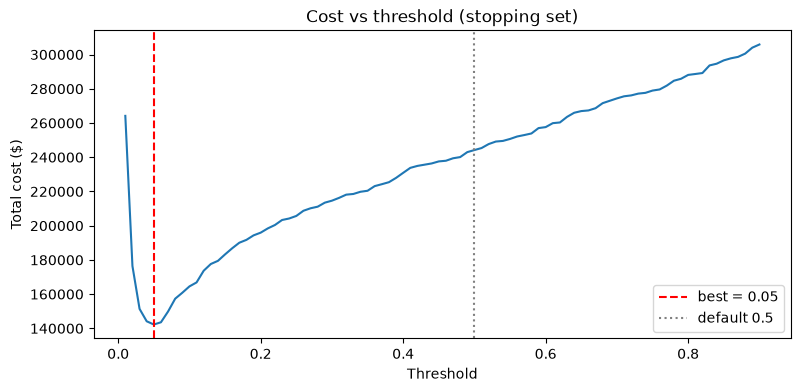

In [12]:
FP_COST = 20
FN_FEE = 15

def total_cost(y, p, amt, t):
    flag = p >= t
    fp = (flag & (y == 0)).sum() * FP_COST
    fn = ((~flag) & (y == 1)) * (amt + FN_FEE)
    return fp + fn.sum()

# predictions on the stopping set, using the model with new features
p_stop = booster2.predict(stop_part[features2], num_iteration=booster2.best_iteration)

y_s, a_s = stop_part[target].values, stop_part["TransactionAmt"].values
thresholds = np.linspace(0.01, 0.9, 90)
costs = [total_cost(y_s, p_stop, a_s, t) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]
print("Best threshold (chosen on stopping set):", round(best_t, 2))

import matplotlib.pyplot as plt
plt.figure(figsize=(9, 4))
plt.plot(thresholds, costs)
plt.axvline(best_t, ls="--", c="red", label=f"best = {best_t:.2f}")
plt.axvline(0.5, ls=":", c="grey", label="default 0.5")
plt.xlabel("Threshold"); plt.ylabel("Total cost ($)")
plt.title("Cost vs threshold (stopping set)"); plt.legend(); plt.show()

In [13]:
from sklearn.metrics import precision_score, recall_score

y_v, a_v = valid[target].values, valid["TransactionAmt"].values

rows = []
for name, t in [("No model (approve all)", 1.01), ("Default 0.5", 0.5), ("Cost-optimal", best_t)]:
    flag = p_valid2 >= t
    rows.append({
        "rule": name,
        "threshold": round(t, 2),
        "flagged": int(flag.sum()),
        "precision": round(precision_score(y_v, flag, zero_division=0), 3),
        "recall": round(recall_score(y_v, flag), 3),
        "total_cost_$": round(total_cost(y_v, p_valid2, a_v, t)),
    })
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

                  rule  threshold  flagged  precision  recall  total_cost_$
No model (approve all)       1.01        0      0.000   0.000        580714
           Default 0.5       0.50     1409      0.811   0.325        453207
          Cost-optimal       0.05     7340      0.312   0.651        298888


In [15]:
import os
os.makedirs("../results", exist_ok=True)
summary.to_csv("../results/threshold_summary.csv", index=False)

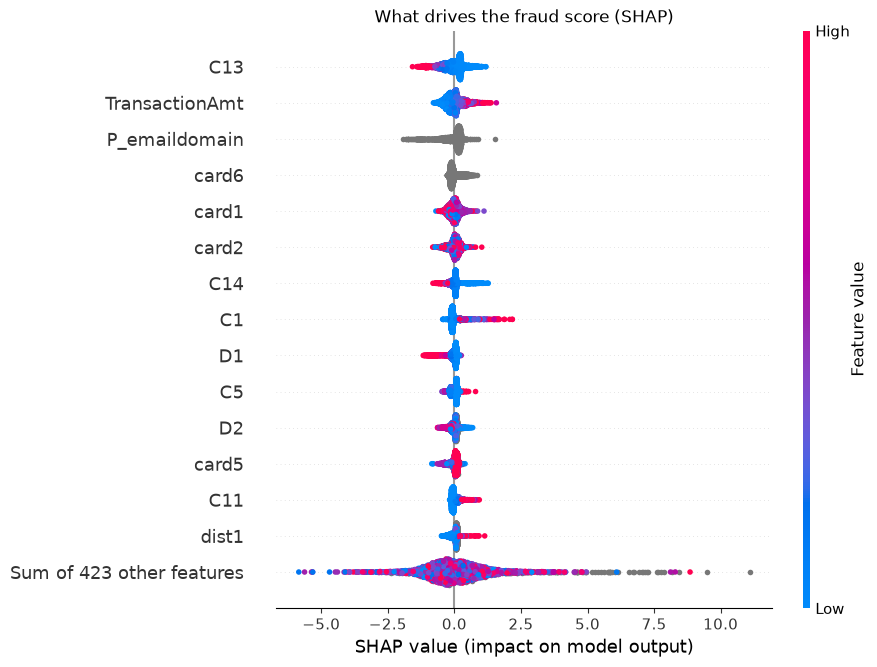

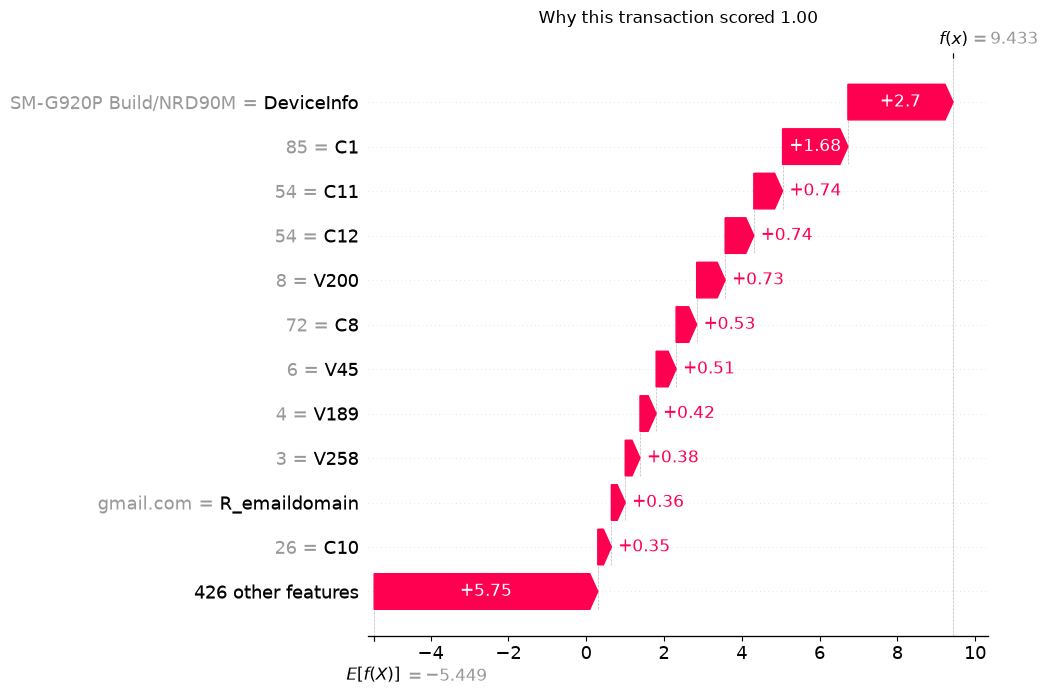

TOP FEATURES OVERALL
       feature  mean_abs_shap
           C13          0.307
TransactionAmt          0.235
 P_emaildomain          0.194
         card6          0.156
         card1          0.142
         card2          0.140
           C14          0.129
            C1          0.125
            D1          0.112
            C5          0.111
            D2          0.103
         card5          0.102

THE FLAGGED TRANSACTION, score 1.0
   feature                 value     shap
DeviceInfo SM-G920P Build/NRD90M 2.703187
        C1                  85.0 1.679587
       C11                  54.0 0.739269
       C12                  54.0 0.736826
      V200                   8.0 0.732485
        C8                  72.0 0.528813
       V45                   6.0 0.513018
      V189                   4.0 0.415381


In [18]:
import shap, os
import matplotlib.pyplot as plt
os.makedirs("../figures", exist_ok=True)

# 1. compute SHAP on a sample of 5,000 validation rows
X_sample = valid[features2].sample(5000, random_state=42)
explainer = shap.TreeExplainer(booster2)
sv = explainer(X_sample)

# 2. pick the highest-scoring real fraud in the sample
scores = booster2.predict(X_sample, num_iteration=booster2.best_iteration)
y_sample = valid.loc[X_sample.index, target].values
idx = int(np.argmax(np.where(y_sample == 1, scores, -1)))

# 3. save the two charts (for your portfolio)
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("What drives the fraud score (SHAP)")
plt.savefig("../figures/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

shap.plots.waterfall(sv[idx], max_display=12, show=False)
plt.title(f"Why this transaction scored {scores[idx]:.2f}")
plt.savefig("../figures/shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. print the text versions (send me these)
top = pd.DataFrame({
    "feature": X_sample.columns,
    "mean_abs_shap": np.abs(sv.values).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)
print("TOP FEATURES OVERALL")
print(top.head(12).round(3).to_string(index=False))

case = pd.DataFrame({
    "feature": X_sample.columns,
    "value": X_sample.iloc[idx].values,
    "shap": sv.values[idx],
}).sort_values("shap", key=abs, ascending=False)
print("\nTHE FLAGGED TRANSACTION, score", round(scores[idx], 3))
print(case.head(8).to_string(index=False))

INPUT DRIFT (train vs valid)
       feature   psi status
           D15 0.049 stable
            D4 0.030 stable
           D10 0.026 stable
            D1 0.023 stable
           C13 0.019 stable
            D2 0.015 stable
            C2 0.012 stable
           C11 0.011 stable
            C1 0.009 stable
         card5 0.009 stable
         card2 0.008 stable
           C14 0.005 stable
     amt_cents 0.004 stable
TransactionAmt 0.004 stable
         card1 0.003 stable
         dist1 0.003 stable
          V294 0.003 stable
         addr1 0.002 stable
            C5 0.002 stable
           V70 0.000 stable

WEEKLY PERFORMANCE
         rows  fraud_rate  pr_auc
week                             
0     20378.0       0.032   0.569
1     20740.0       0.028   0.513
2     20944.0       0.033   0.478
3     20206.0       0.037   0.548
4     17681.0       0.042   0.583
5      2754.0       0.043   0.538


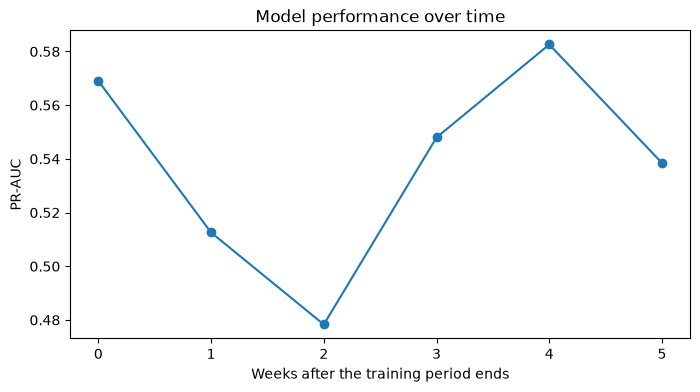

In [19]:
def psi(expected, actual, bins=10):
    expected, actual = pd.Series(expected).dropna(), pd.Series(actual).dropna()
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return np.nan
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual.clip(edges[0], edges[-1]), edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

# 1. input drift on the top numeric features
num_top = [f for f in top["feature"].head(25) if pd.api.types.is_numeric_dtype(train[f])]
drift = pd.DataFrame({
    "feature": num_top,
    "psi": [psi(train[f], valid[f]) for f in num_top],
}).sort_values("psi", ascending=False)
drift["status"] = pd.cut(drift["psi"], [-1, 0.1, 0.25, 99], labels=["stable", "watch", "shifted"])
print("INPUT DRIFT (train vs valid)")
print(drift.round(3).to_string(index=False))

# 2. performance week by week in the validation period
valid_scored = valid.assign(p=p_valid2, week=(valid["day"] - valid["day"].min()) // 7)
weekly = valid_scored.groupby("week").apply(
    lambda d: pd.Series({
        "rows": len(d),
        "fraud_rate": d[target].mean(),
        "pr_auc": average_precision_score(d[target], d["p"]),
    })
)
print("\nWEEKLY PERFORMANCE")
print(weekly.round(3).to_string())

# 3. chart for the portfolio
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(weekly.index, weekly["pr_auc"], marker="o")
ax.set_xlabel("Weeks after the training period ends")
ax.set_ylabel("PR-AUC")
ax.set_title("Model performance over time")
plt.savefig("../figures/weekly_performance.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
booster2.save_model("../results/lgbm_model.txt")
weekly.to_csv("../results/weekly_performance.csv")
drift.to_csv("../results/drift_psi.csv", index=False)

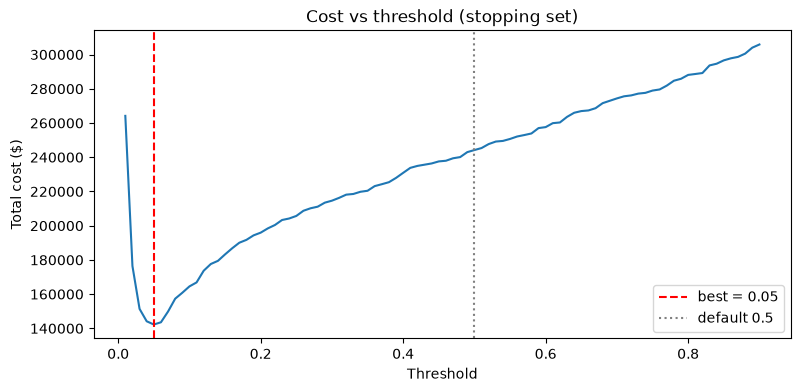

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import os

os.makedirs("../figures", exist_ok=True)

FP_COST = 20
FN_FEE = 15

def total_cost(y, p, amt, t):
    flag = p >= t
    fp = (flag & (y == 0)).sum() * FP_COST
    fn = ((~flag) & (y == 1)) * (amt + FN_FEE)
    return fp + fn.sum()

p_stop = booster2.predict(stop_part[features2], num_iteration=booster2.best_iteration)
y_s = stop_part[target].values
a_s = stop_part["TransactionAmt"].values

thresholds = np.linspace(0.01, 0.9, 90)
costs = [total_cost(y_s, p_stop, a_s, t) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]

plt.figure(figsize=(9, 4))
plt.plot(thresholds, costs)
plt.axvline(best_t, ls="--", c="red", label=f"best = {best_t:.2f}")
plt.axvline(0.5, ls=":", c="grey", label="default 0.5")
plt.xlabel("Threshold")
plt.ylabel("Total cost ($)")
plt.title("Cost vs threshold (stopping set)")
plt.legend()
plt.savefig("../figures/cost_vs_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
import os

os.makedirs("../results", exist_ok=True)

booster2.save_model("../results/lgbm_model.txt")
weekly.to_csv("../results/weekly_performance.csv")
drift.to_csv("../results/drift_psi.csv", index=False)
summary.to_csv("../results/threshold_summary.csv", index=False)

print(os.listdir("../figures"))
print(os.listdir("../results"))

['cost_vs_threshold.png', 'fraud_over_time.png', 'shap_beeswarm.png', 'weekly_performance.png', 'shap_waterfall.png']
['threshold_summary.csv', 'lgbm_model.txt', 'weekly_performance.csv', 'drift_psi.csv']
